Loaded LS_sim_no_noise_linear_friction: 2399 steps
Loaded HNN_sim_no_noise_linear_friction: 500 steps


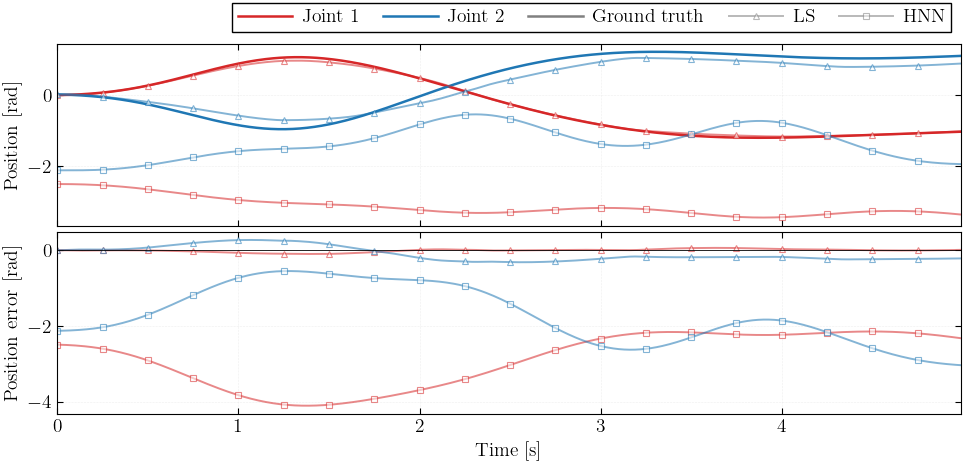

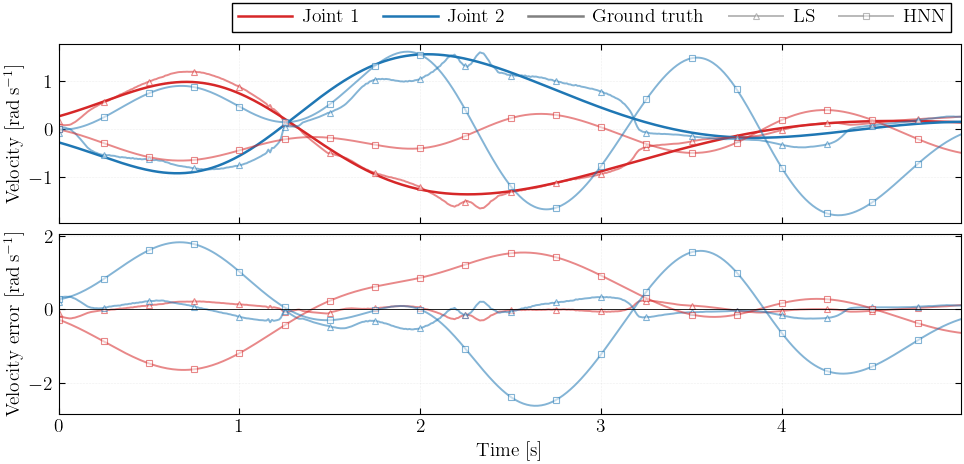

In [1]:
## PLOTTING FOR HNN AND LS

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# IEEE STYLE
# ============================================================
mpl.rcdefaults()
mpl.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "font.size": 14,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "legend.fontsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.top": True,
    "ytick.right": True,
    "axes.grid": True,
    "grid.linewidth": 0.4,
    "grid.alpha": 0.4,
    "grid.linestyle": ":",
    "lines.linewidth": 1.4,
    "legend.frameon": True,
    "legend.framealpha": 1.0,
    "legend.edgecolor": "black",
    "legend.fancybox": False,
    "legend.handlelength": 2.8,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
})

# ============================================================
# LOAD MODELS
# ============================================================
model_files = [
    "results_LS_sim_no_noise_linear_friction.npz",
    "results_HNN_sim_no_noise_linear_friction.npz",
    # "results_baseline.npz",   # add more as needed
]



models = {}
for f in model_files:
    d = np.load(f, allow_pickle=True)
    name = str(d["model_name"])
    models[name] = d
    print(f"Loaded {name}: {len(d['true_theta1'])} steps")

ref = list(models.values())[0]
dt = float(ref["dt"])
T = min(len(ref["true_theta1"]),
        *[len(m["pred_theta1"]) for m in models.values()])
time = np.arange(T) * dt

# ============================================================
# VISUAL ENCODING
#   Colour = joint  (red = joint 1, blue = joint 2)
#   Truth  = full opacity, solid, no marker
#   HNN    = reduced alpha, square markers
#   LS     = reduced alpha, triangle markers
# ============================================================
C_J1 = "#D62728"   # red
C_J2 = "#1F77B4"   # blue

GT_LW = 1.8
MD_LW = 1.4
ALPHA_MODEL = 0.55

N_MARKER = max(1, T // 20)

MODEL_CFG = {
    # name: (marker, alpha, display_label)
    "LS_sim_no_noise_linear_friction":  ("^", ALPHA_MODEL, "LS"),
    "HNN_sim_no_noise_linear_friction": ("s", ALPHA_MODEL, "HNN"),
}

# Fallback
_FALLBACK_MK = ["^", "s", "D", "v", "o"]
for i, name in enumerate(models):
    if name not in MODEL_CFG:
        MODEL_CFG[name] = (_FALLBACK_MK[i % len(_FALLBACK_MK)],
                           ALPHA_MODEL, name.replace("_", r"\_"))

FIG_W = 10


def _plot_line(ax, t, y, color, lw, alpha=1.0, marker=None):
    """Helper to plot with optional sparse markers."""
    kw = dict(color=color, lw=lw, alpha=alpha)
    if marker:
        kw.update(marker=marker, markevery=N_MARKER, markersize=4.5,
                  markerfacecolor="white", markeredgewidth=0.8,
                  markeredgecolor=color)
    ax.plot(t, y, **kw)


# ============================================================
# FIGURE 1 — POSITION + POSITION ERROR
# ============================================================
fig1, (ax_pos, ax_epos) = plt.subplots(2, 1, figsize=(FIG_W, 5), sharex=True)

# ---- Position: ground truth (solid, full opacity) ----
_plot_line(ax_pos, time, ref["true_theta1"][:T], C_J1, GT_LW)
_plot_line(ax_pos, time, ref["true_theta2"][:T], C_J2, GT_LW)

# ---- Position: model predictions ----
for name, data in models.items():
    mk, alph, _ = MODEL_CFG[name]
    _plot_line(ax_pos, time, data["pred_theta1"][:T], C_J1, MD_LW, alph, mk)
    _plot_line(ax_pos, time, data["pred_theta2"][:T], C_J2, MD_LW, alph, mk)

ax_pos.set_ylabel(r"Position [rad]")

# ---- Position error (no ground truth) ----
for name, data in models.items():
    mk, alph, _ = MODEL_CFG[name]
    err_t1 = data["pred_theta1"][:T] - ref["true_theta1"][:T]
    err_t2 = data["pred_theta2"][:T] - ref["true_theta2"][:T]
    _plot_line(ax_epos, time, err_t1, C_J1, MD_LW, alph, mk)
    _plot_line(ax_epos, time, err_t2, C_J2, MD_LW, alph, mk)

ax_epos.axhline(0, color="black", ls="-", lw=0.6)
ax_epos.set_ylabel(r"Position error [rad]")
ax_epos.set_xlabel(r"Time [s]")

# ---- Shared legend ----
h_joint = [
    Line2D([], [], color=C_J1, ls="-", lw=GT_LW, label=r"Joint 1"),
    Line2D([], [], color=C_J2, ls="-", lw=GT_LW, label=r"Joint 2"),
]
h_source = [
    Line2D([], [], color="gray", ls="-", lw=GT_LW,
           marker="None", label="Ground truth"),
]
for name in models:
    mk, alph, lbl = MODEL_CFG[name]
    h_source.append(
        Line2D([], [], color="gray", ls="-", lw=MD_LW, alpha=alph,
               marker=mk, markersize=4.5,
               markerfacecolor="white", markeredgewidth=0.8,
               markeredgecolor="gray", label=lbl)
    )

# ---- Figure 1 ----
ax_pos.set_xlim(time[0], time[-1])

leg1 = ax_pos.legend(
    handles=h_joint + h_source,
    loc="lower right",
    bbox_to_anchor=(1.0, 1.01),
    ncol=len(h_joint) + len(h_source),
    columnspacing=1.2,
    handletextpad=0.5,
    borderpad=0.3,
)

plt.tight_layout(h_pad=0.3)
fig1.savefig("position_comparison.png", format="png", dpi=600)
plt.show()


# ============================================================
# FIGURE 2 — VELOCITY + VELOCITY ERROR
# ============================================================
fig2, (ax_vel, ax_evel) = plt.subplots(2, 1, figsize=(FIG_W, 5), sharex=True)

# ---- Velocity: ground truth ----
_plot_line(ax_vel, time, ref["true_dtheta1"][:T], C_J1, GT_LW)
_plot_line(ax_vel, time, ref["true_dtheta2"][:T], C_J2, GT_LW)

# ---- Velocity: model predictions ----
for name, data in models.items():
    mk, alph, _ = MODEL_CFG[name]
    _plot_line(ax_vel, time, data["pred_dtheta1"][:T], C_J1, MD_LW, alph, mk)
    _plot_line(ax_vel, time, data["pred_dtheta2"][:T], C_J2, MD_LW, alph, mk)

ax_vel.set_ylabel(r"Velocity [rad\,s$^{-1}$]")

# ---- Velocity error (no ground truth) ----
for name, data in models.items():
    mk, alph, _ = MODEL_CFG[name]
    err_d1 = data["pred_dtheta1"][:T] - ref["true_dtheta1"][:T]
    err_d2 = data["pred_dtheta2"][:T] - ref["true_dtheta2"][:T]
    _plot_line(ax_evel, time, err_d1, C_J1, MD_LW, alph, mk)
    _plot_line(ax_evel, time, err_d2, C_J2, MD_LW, alph, mk)

ax_evel.axhline(0, color="black", ls="-", lw=0.6)
ax_evel.set_ylabel(r"Velocity error [rad\,s$^{-1}$]")
ax_evel.set_xlabel(r"Time [s]")

# ---- Shared legend (reuse handles) ----
h_joint_vel = [
    Line2D([], [], color=C_J1, ls="-", lw=GT_LW, label=r"Joint 1"),
    Line2D([], [], color=C_J2, ls="-", lw=GT_LW, label=r"Joint 2"),
]

ax_vel.set_xlim(time[0], time[-1])

leg2 = ax_vel.legend(
    handles=h_joint_vel + h_source,
    loc="lower right",
    bbox_to_anchor=(1.0, 1.01),
    ncol=len(h_joint_vel) + len(h_source),
    columnspacing=1.2,
    handletextpad=0.5,
    borderpad=0.3,
)

plt.tight_layout(h_pad=0.3)
fig2.savefig("velocity_comparison.png", format="png", dpi=600)
plt.show()

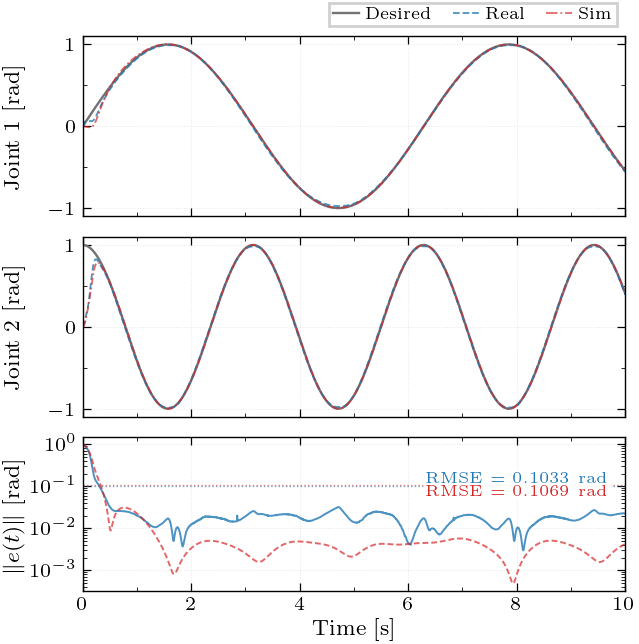

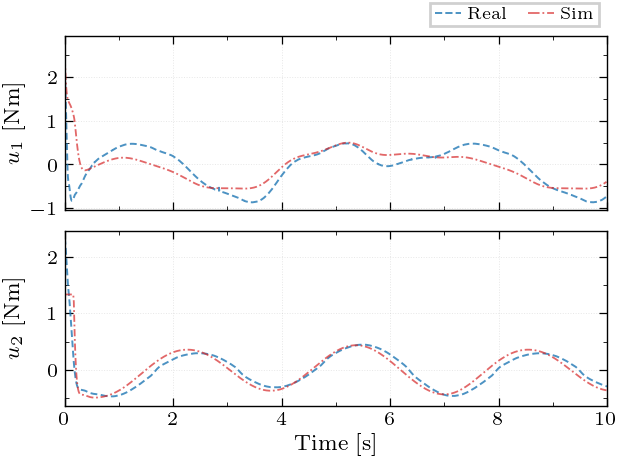

RMSE real = 0.10331 rad  (5.919 deg)
RMSE sim  = 0.10686 rad  (6.122 deg)


In [60]:
# ── Sim-to-Real comparison plot  (IEEE, LaTeX rendering) ─────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator, LogLocator
from scipy.io import loadmat
from pathlib import Path

# ═══════════════════════════════════════════════════════════════════════
# IEEE figure sizing
# ═══════════════════════════════════════════════════════════════════════
COL_W  = 3.5
FIG1_H = 3.6
FIG2_H = 2.4

# ── Global rc  (LaTeX text rendering) ────────────────────────────────
mpl.rcParams.update({
    'text.usetex':        True,
    'text.latex.preamble': r'\usepackage{amsmath}\usepackage{amssymb}',
    'font.family':        'serif',
    'font.serif':         ['Computer Modern Roman'],
    'font.size':          8,
    'axes.labelsize':     8,
    'axes.titlesize':     9,
    'legend.fontsize':    6,
    'xtick.labelsize':    7,
    'ytick.labelsize':    7,
    'lines.linewidth':    0.75,
    'axes.linewidth':     0.5,
    'axes.grid':          True,
    'axes.grid.which':    'major',
    'grid.alpha':         0.30,
    'grid.linewidth':     0.35,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   3,
    'ytick.major.size':   3,
    'xtick.minor.size':   1.5,
    'ytick.minor.size':   1.5,
    'xtick.major.width':  0.45,
    'ytick.major.width':  0.45,
    'xtick.minor.width':  0.3,
    'ytick.minor.width':  0.3,
    'xtick.top':          True,
    'ytick.right':        True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.labelpad':      2.0,
    'xtick.major.pad':    2.0,
    'ytick.major.pad':    2.0,
    'legend.frameon':       True,
    'legend.framealpha':    0.92,
    'legend.edgecolor':     '0.80',
    'legend.fancybox':      False,
    'legend.borderpad':     0.3,
    'legend.handlelength':  1.6,
    'legend.handletextpad': 0.4,
    'legend.columnspacing': 0.8,
    'legend.labelspacing':  0.25,
    'figure.dpi':         200,
    'savefig.dpi':        600,
    'savefig.bbox':       'tight',
    'savefig.pad_inches': 0.015,
    'pdf.fonttype':       42,
    'ps.fonttype':        42,
})

# ── Colours ──────────────────────────────────────────────────────────
c_des  = '0.45'       # grey
c_real = '#1f77b4'    # blue
c_sim  = '#d62728'    # red
A_REAL = 0.8
A_SIM  = 0.7

# ── Load data ────────────────────────────────────────────────────────
real_path = '/Users/lars/Documents/GitHub/Master-Research-Project/Python Code/KPES_pert_a1_0.000_a2_0.000.mat'
sim_path  = '/Users/lars/Documents/GitHub/Master-Research-Project/Python Code/KPES_sim.mat'

mat_real = loadmat(real_path)
mat_sim  = loadmat(sim_path)

t_real      = mat_real['t'].flatten()
q_des_real  = mat_real['q_desired']
q_meas_real = mat_real['q_meas']
e_real      = mat_real['e_track']
e_norm_real = np.linalg.norm(e_real, axis=1)
u_real      = mat_real['u_total']

t_sim      = mat_sim['t'].flatten()
q_meas_sim = mat_sim['q_meas']
e_sim      = mat_sim['e_track']
e_norm_sim = np.linalg.norm(e_sim, axis=1)
u_sim      = mat_sim['u_total']

# Trim final zero-filled sample from simulation
t_sim      = t_sim[:-1]
q_meas_sim = q_meas_sim[:-1, :]
e_sim      = e_sim[:-1, :]
e_norm_sim = e_norm_sim[:-1]
u_sim      = u_sim[:-1, :]

# ═══════════════════════════════════════════════════════════════════════
# Figure 1 – Position tracking + error norm
# ═══════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(
    3, 1, figsize=(COL_W, FIG1_H), sharex=True,
    gridspec_kw={'height_ratios': [1, 1, 0.85], 'hspace': 0.12},
)

for j, ax in enumerate(axes[:2]):
    ax.plot(t_real, q_des_real[:, j],  color=c_des,  linewidth=0.85)
    ax.plot(t_real, q_meas_real[:, j], color=c_real,  linewidth=0.65,
            alpha=A_REAL, linestyle='--', dashes=(3.5, 1.8))
    ax.plot(t_sim,  q_meas_sim[:, j],  color=c_sim,   linewidth=0.65,
            alpha=A_SIM, linestyle='-.', dashes=(4, 1.5, 1, 1.5))
    ax.set_ylabel(r'Joint %d [rad]' % (j+1))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))

# Error norm
axes[2].plot(t_real, e_norm_real, color=c_real, linewidth=0.7, alpha=A_REAL)
axes[2].plot(t_sim,  e_norm_sim,  color=c_sim,  linewidth=0.7, alpha=A_SIM,
             linestyle='--', dashes=(3, 1.5))
axes[2].set_yscale('log')
axes[2].set_ylabel(r'$\|e(t)\|$ [rad]')
axes[2].set_xlabel(r'Time [s]')

rms_real = np.sqrt(np.mean(e_norm_real**2))
rms_sim  = np.sqrt(np.mean(e_norm_sim[1:]**2))

axes[2].axhline(rms_real, color=c_real, ls=':', lw=0.5, alpha=0.55)
axes[2].axhline(rms_sim,  color=c_sim,  ls=':', lw=0.5, alpha=0.55)

axes[2].annotate(
    r'RMSE $= %.4f$ rad' % rms_real,
    xy=(0.97, rms_real), xycoords=('axes fraction', 'data'),
    fontsize=5.5, color=c_real, ha='right', va='bottom',
    bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.75))
axes[2].annotate(
    r'RMSE $= %.4f$ rad' % rms_sim,
    xy=(0.97, rms_sim), xycoords=('axes fraction', 'data'),
    fontsize=5.5, color=c_sim, ha='right', va='top',
    bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.75))

axes[2].xaxis.set_minor_locator(AutoMinorLocator(2))
axes[2].yaxis.set_major_locator(LogLocator(base=10, numticks=8))
axes[2].yaxis.set_minor_locator(
    LogLocator(base=10, subs=np.arange(2, 10)*0.1, numticks=12))
axes[2].yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

# ── Shared top legend ────────────────────────────────────────────────
handles = [
    Line2D([], [], color=c_des,  ls='-',  lw=0.85,            label='Desired'),
    Line2D([], [], color=c_real, ls='--', lw=0.65, alpha=A_REAL, label='Real'),
    Line2D([], [], color=c_sim,  ls='-.', lw=0.65, alpha=A_SIM,  label='Sim'),
]
axes[0].legend(
    handles=handles,
    loc='lower right',
    bbox_to_anchor=(1.0, 1.01),
    ncol=3,
    columnspacing=1.2,
    handletextpad=0.4,
    borderpad=0.25,
)

for ax in axes:
    ax.set_xlim(t_real[0], t_real[-1])

fig.align_ylabels(axes)

out_dir = Path(real_path).parent
fig.savefig(str(out_dir / 'sim2real_tracking.pdf'))
fig.savefig(str(out_dir / 'sim2real_tracking.png'))
plt.show()

# ═══════════════════════════════════════════════════════════════════════
# Figure 2 – Control input comparison
# ═══════════════════════════════════════════════════════════════════════
fig2, axes2 = plt.subplots(
    2, 1, figsize=(COL_W, FIG2_H), sharex=True,
    gridspec_kw={'hspace': 0.12},
)

for j, ax in enumerate(axes2):
    ax.plot(t_real, u_real[:, j], color=c_real, linewidth=0.7, alpha=A_REAL,
            linestyle='--', dashes=(3.5, 1.8))
    ax.plot(t_sim,  u_sim[:, j],  color=c_sim,  linewidth=0.65, alpha=A_SIM,
            linestyle='-.', dashes=(4, 1.5, 1, 1.5))
    ax.set_ylabel(r'$u_%d$ [Nm]' % (j+1))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.set_xlim(t_real[0], t_real[-1])

axes2[1].set_xlabel(r'Time [s]')

handles_u = [
    Line2D([], [], color=c_real, ls='--', lw=0.7, alpha=A_REAL, label='Real'),
    Line2D([], [], color=c_sim,  ls='-.', lw=0.65, alpha=A_SIM, label='Sim'),
]
axes2[0].legend(
    handles=handles_u,
    loc='lower right',
    bbox_to_anchor=(1.0, 1.01),
    ncol=2,
    columnspacing=1.2,
    handletextpad=0.4,
    borderpad=0.25,
)

fig2.align_ylabels(axes2)

fig2.savefig(str(out_dir / 'sim2real_control.pdf'))
fig2.savefig(str(out_dir / 'sim2real_control.png'))
plt.show()

print(r'RMSE real = %.5f rad  (%.3f deg)' % (rms_real, np.rad2deg(rms_real)))
print(r'RMSE sim  = %.5f rad  (%.3f deg)' % (rms_sim,  np.rad2deg(rms_sim)))

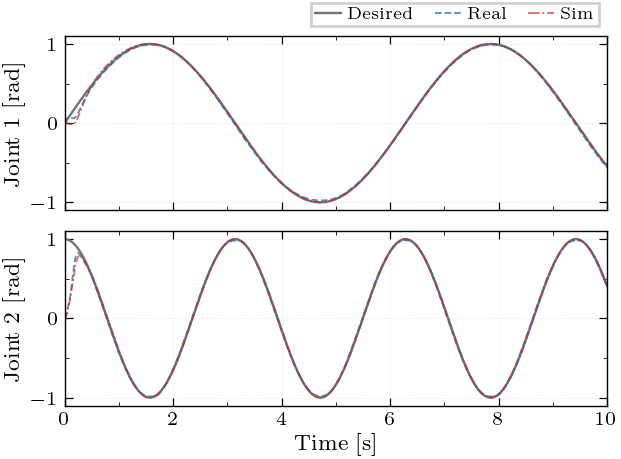

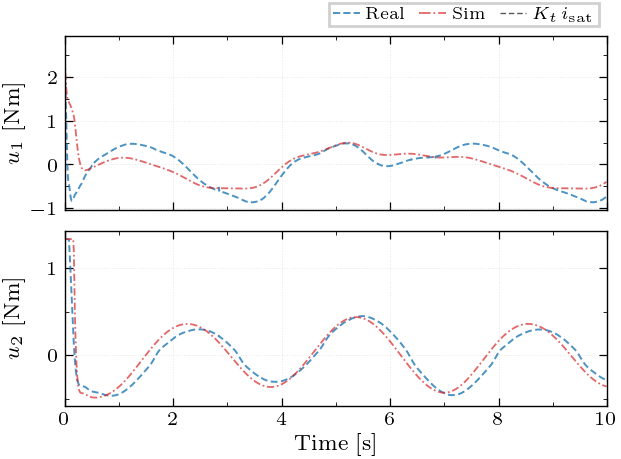

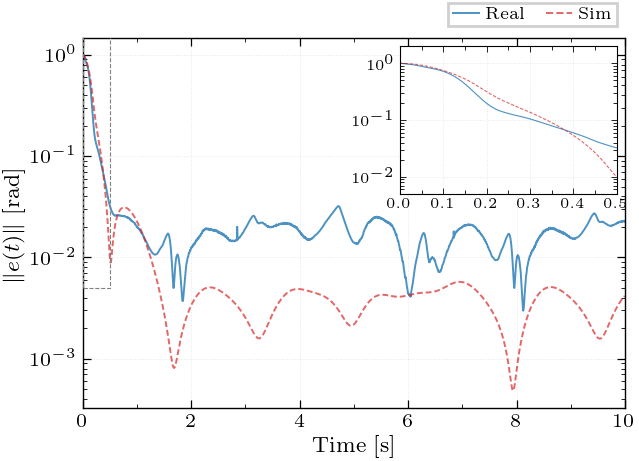

RMSE real = 0.10331 rad  (5.919 deg)
RMSE sim  = 0.10686 rad  (6.122 deg)


In [23]:
# ── Sim-to-Real: three separate IEEE figures ─────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import AutoMinorLocator, LogLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.io import loadmat
from pathlib import Path

# ═══════════════════════════════════════════════════════════════════════
# IEEE style
# ═══════════════════════════════════════════════════════════════════════
COL_W = 3.5

mpl.rcParams.update({
    'text.usetex':        True,
    'text.latex.preamble': r'\usepackage{amsmath}\usepackage{amssymb}',
    'font.family':        'serif',
    'font.serif':         ['Computer Modern Roman'],
    'font.size':          8,
    'axes.labelsize':     8,
    'axes.titlesize':     9,
    'legend.fontsize':    6,
    'xtick.labelsize':    7,
    'ytick.labelsize':    7,
    'lines.linewidth':    0.75,
    'axes.linewidth':     0.5,
    'axes.grid':          True,
    'axes.grid.which':    'major',
    'grid.alpha':         0.30,
    'grid.linewidth':     0.35,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   3,
    'ytick.major.size':   3,
    'xtick.minor.size':   1.5,
    'ytick.minor.size':   1.5,
    'xtick.major.width':  0.45,
    'ytick.major.width':  0.45,
    'xtick.minor.width':  0.3,
    'ytick.minor.width':  0.3,
    'xtick.top':          True,
    'ytick.right':        True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.labelpad':      2.0,
    'xtick.major.pad':    2.0,
    'ytick.major.pad':    2.0,
    'legend.frameon':       True,
    'legend.framealpha':    0.92,
    'legend.edgecolor':     '0.80',
    'legend.fancybox':      False,
    'legend.borderpad':     0.3,
    'legend.handlelength':  1.6,
    'legend.handletextpad': 0.4,
    'legend.columnspacing': 0.8,
    'legend.labelspacing':  0.25,
    'figure.dpi':         200,
    'savefig.dpi':        600,
    'savefig.bbox':       'tight',
    'savefig.pad_inches': 0.015,
    'pdf.fonttype':       42,
    'ps.fonttype':        42,
})

# ── Colours ──────────────────────────────────────────────────────────
c_des  = '0.45'
c_real = '#1f77b4'
c_sim  = '#d62728'
c_sat  = '0.35'
A_REAL = 0.8
A_SIM  = 0.7

# ── Torque saturation ────────────────────────────────────────────────
Kt1, i_sat1 = 3.018583, 0.92
Kt2, i_sat2 = 1.111065, 1.2
u_max = [Kt1 * i_sat1, Kt2 * i_sat2]

# ── Load data ────────────────────────────────────────────────────────
real_path = '/Users/lars/Documents/GitHub/Master-Research-Project/Python Code/KPES_pert_a1_0.000_a2_0.000.mat'
sim_path  = '/Users/lars/Documents/GitHub/Master-Research-Project/Python Code/KPES_sim.mat'

mat_real = loadmat(real_path)
mat_sim  = loadmat(sim_path)

t_real      = mat_real['t'].flatten()
q_des_real  = mat_real['q_desired']
q_meas_real = mat_real['q_meas']
e_real      = mat_real['e_track']
e_norm_real = np.linalg.norm(e_real, axis=1)
u_real      = mat_real['u_total']

t_sim      = mat_sim['t'].flatten()
q_meas_sim = mat_sim['q_meas']
e_sim      = mat_sim['e_track']
e_norm_sim = np.linalg.norm(e_sim, axis=1)
u_sim      = mat_sim['u_total']

# Trim final zero-filled sample
t_sim      = t_sim[:-1]
q_meas_sim = q_meas_sim[:-1, :]
e_sim      = e_sim[:-1, :]
e_norm_sim = e_norm_sim[:-1]
u_sim      = u_sim[:-1, :]

out_dir = Path(real_path).parent

# ── Legend handles (reused) ──────────────────────────────────────────
h_track = [
    Line2D([], [], color=c_des,  ls='-',  lw=0.85,              label='Desired'),
    Line2D([], [], color=c_real, ls='--', lw=0.65, alpha=A_REAL, label='Real'),
    Line2D([], [], color=c_sim,  ls='-.', lw=0.65, alpha=A_SIM,  label='Sim'),
]
h_ctrl = [
    Line2D([], [], color=c_real, ls='--', lw=0.7,  alpha=A_REAL, label='Real'),
    Line2D([], [], color=c_sim,  ls='-.', lw=0.65, alpha=A_SIM,  label='Sim'),
    Line2D([], [], color=c_sat,  ls='--', dashes=(4, 2), lw=0.5, label=r'$K_t \, i_{\mathrm{sat}}$'),
]
h_err = [
    Line2D([], [], color=c_real, ls='-', lw=0.7,  alpha=A_REAL, label='Real'),
    Line2D([], [], color=c_sim,  ls='--', lw=0.7, alpha=A_SIM,  label='Sim'),
]

# ═══════════════════════════════════════════════════════════════════════
# Figure 1 – Position tracking  (Joint 1 & 2)
# ═══════════════════════════════════════════════════════════════════════
fig1, axes1 = plt.subplots(
    2, 1, figsize=(COL_W, 2.4), sharex=True,
    gridspec_kw={'hspace': 0.12},
)

for j, ax in enumerate(axes1):
    ax.plot(t_real, q_des_real[:, j],  color=c_des,  linewidth=0.85)
    ax.plot(t_real, q_meas_real[:, j], color=c_real,  linewidth=0.65,
            alpha=A_REAL, linestyle='--', dashes=(3.5, 1.8))
    ax.plot(t_sim,  q_meas_sim[:, j],  color=c_sim,   linewidth=0.65,
            alpha=A_SIM, linestyle='-.', dashes=(4, 1.5, 1, 1.5))
    ax.set_ylabel(r'Joint %d [rad]' % (j+1))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.set_xlim(t_real[0], t_real[-1])

axes1[1].set_xlabel(r'Time [s]')

axes1[0].legend(
    handles=h_track,
    loc='lower right', bbox_to_anchor=(1.0, 1.01),
    ncol=3, columnspacing=1.2, handletextpad=0.4, borderpad=0.25,
)

fig1.align_ylabels(axes1)
fig1.savefig(str(out_dir / 'sim2real_tracking.pdf'))
fig1.savefig(str(out_dir / 'sim2real_tracking.png'))
plt.show()

# ═══════════════════════════════════════════════════════════════════════
# Figure 2 – Control inputs  (u1 & u2) + saturation limits
# ═══════════════════════════════════════════════════════════════════════
fig2, axes2 = plt.subplots(
    2, 1, figsize=(COL_W, 2.4), sharex=True,
    gridspec_kw={'hspace': 0.12},
)

for j, ax in enumerate(axes2):
    ax.plot(t_real, np.minimum(u_real[:, j], u_max[j]), color=c_real, linewidth=0.7, alpha=A_REAL,
            linestyle='--', dashes=(3.5, 1.8))
    ax.plot(t_sim,  u_sim[:, j],  color=c_sim,  linewidth=0.65, alpha=A_SIM,
            linestyle='-.', dashes=(4, 1.5, 1, 1.5))
    # ax.axhline( u_max[j], color=c_sat, ls='--', lw=0.5, dashes=(4, 2))
    # ax.axhline(-u_max[j], color=c_sat, ls='--', lw=0.5, dashes=(4, 2))
    ax.set_ylabel(r'$u_%d$ [Nm]' % (j+1))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.set_xlim(t_real[0], t_real[-1])

axes2[1].set_xlabel(r'Time [s]')

axes2[0].legend(
    handles=h_ctrl,
    loc='lower right', bbox_to_anchor=(1.0, 1.01),
    ncol=3, columnspacing=0.8, handletextpad=0.4, borderpad=0.25,
)

fig2.align_ylabels(axes2)
fig2.savefig(str(out_dir / 'sim2real_control.pdf'))
fig2.savefig(str(out_dir / 'sim2real_control.png'))
plt.show()

# ═══════════════════════════════════════════════════════════════════════
# Figure 3 – Error norm  (full size, with inset zoom at origin)
# ═══════════════════════════════════════════════════════════════════════
fig3, ax3 = plt.subplots(figsize=(COL_W, 2.4))

ax3.plot(t_real, e_norm_real, color=c_real, linewidth=0.7, alpha=A_REAL)
ax3.plot(t_sim,  e_norm_sim,  color=c_sim,  linewidth=0.7, alpha=A_SIM,
         linestyle='--', dashes=(3, 1.5))

ax3.set_yscale('log')
ax3.set_ylabel(r'$\|e(t)\|$ [rad]')
ax3.set_xlabel(r'Time [s]')
ax3.set_xlim(t_real[0], t_real[-1])

ax3.yaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax3.yaxis.set_minor_locator(
    LogLocator(base=10, subs=np.arange(2, 10)*0.1, numticks=12))
ax3.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax3.xaxis.set_minor_locator(AutoMinorLocator(2))

# RMSE
rms_real = np.sqrt(np.mean(e_norm_real**2))
rms_sim  = np.sqrt(np.mean(e_norm_sim[1:]**2))

# ax3.axhline(rms_real, color=c_real, ls=':', lw=0.5, alpha=0.55)
# ax3.axhline(rms_sim,  color=c_sim,  ls=':', lw=0.5, alpha=0.55)

# ax3.annotate(
#     r'RMSE $= %.4f$ rad' % rms_real,
#     xy=(0.03, 0.95), xycoords='axes fraction',
#     fontsize=5.5, color=c_real, ha='left', va='top',
#     bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))
# ax3.annotate(
#     r'RMSE $= %.4f$ rad' % rms_sim,
#     xy=(0.03, 0.82), xycoords='axes fraction',
#     fontsize=5.5, color=c_sim, ha='left', va='top',
#     bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))

# Legend
ax3.legend(
    handles=h_err,
    loc='lower right', bbox_to_anchor=(1.0, 1.01),
    ncol=2, columnspacing=1.2, handletextpad=0.4, borderpad=0.25,
)

# ── Inset zoom at origin ────────────────────────────────────────────
ZOOM_T = (0.0, 0.5)

ax_ins = inset_axes(ax3, width='40%', height='40%',
                    loc='upper right', borderpad=0.5)

ax_ins.plot(t_real, e_norm_real, color=c_real, linewidth=0.4, alpha=A_REAL)
ax_ins.plot(t_sim,  e_norm_sim,  color=c_sim,  linewidth=0.4, alpha=A_SIM,
            linestyle='--', dashes=(3, 1.5))

ax_ins.set_xlim(*ZOOM_T)
ax_ins.set_yscale('log')

# Auto y from data in window
y_vals = []
for t_arr, y_arr in [(t_real, e_norm_real), (t_sim, e_norm_sim)]:
    mask = (t_arr >= ZOOM_T[0]) & (t_arr <= ZOOM_T[1])
    y_vals.append(y_arr[mask])
y_all = np.concatenate(y_vals)
y_pos = y_all[y_all > 0]
if len(y_pos) > 0:
    ax_ins.set_ylim(y_pos.min() * 0.5, y_pos.max() * 2.0)

ax_ins.tick_params(labelsize=5, direction='in',
                   length=2, width=0.3, pad=1.5)
ax_ins.xaxis.set_minor_locator(AutoMinorLocator(2))
ax_ins.set_facecolor('white')
for spine in ax_ins.spines.values():
    spine.set_linewidth(0.4)

# Rectangle on parent marking zoom region
yl_ins = ax_ins.get_ylim()
rect = Rectangle((ZOOM_T[0], yl_ins[0]),
                  ZOOM_T[1] - ZOOM_T[0],
                  yl_ins[1] - yl_ins[0],
                  linewidth=0.4, edgecolor='0.5',
                  facecolor='none', linestyle='--', zorder=5)
ax3.add_patch(rect)

fig3.savefig(str(out_dir / 'sim2real_error.pdf'))
fig3.savefig(str(out_dir / 'sim2real_error.png'))
plt.show()

print(r'RMSE real = %.5f rad  (%.3f deg)' % (rms_real, np.rad2deg(rms_real)))
print(r'RMSE sim  = %.5f rad  (%.3f deg)' % (rms_sim,  np.rad2deg(rms_sim)))

Found 5 files
  KPES_pert_a1_0.000_a2_0.000.mat  a1=0.000  a2=0.000
  KPES_pert_a1_0.100_a2_0.200.mat  a1=0.100  a2=0.200
  KPES_pert_a1_0.250_a2_0.500.mat  a1=0.250  a2=0.500
  KPES_pert_a1_0.400_a2_0.800.mat  a1=0.400  a2=0.800
  KPES_pert_a1_0.500_a2_1.000.mat  a1=0.500  a2=1.000


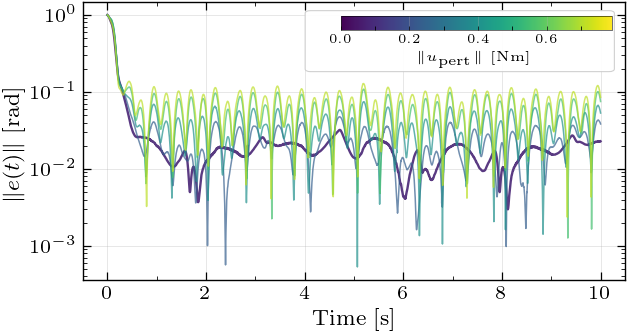

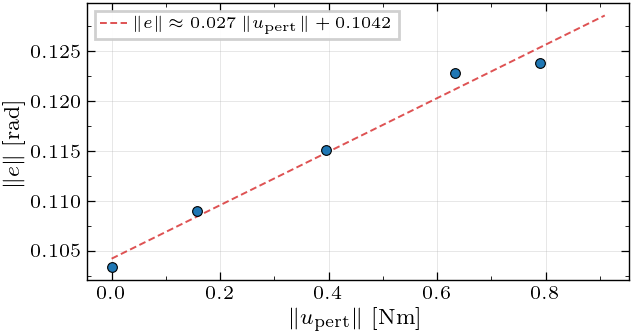

In [34]:
# ── ISS analysis: two separate single-column figures ─────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as mcolors
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import AutoMinorLocator, LogLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.io import loadmat
from pathlib import Path

# ═══════════════════════════════════════════════════════════════════════
# IEEE style
# ═══════════════════════════════════════════════════════════════════════
COL_W = 3.5

mpl.rcParams.update({
    'text.usetex':        True,
    'text.latex.preamble': r'\usepackage{amsmath}\usepackage{amssymb}',
    'font.family':        'serif',
    'font.serif':         ['Computer Modern Roman'],
    'font.size':          8,
    'axes.labelsize':     8,
    'axes.titlesize':     9,
    'legend.fontsize':    6,
    'xtick.labelsize':    7,
    'ytick.labelsize':    7,
    'lines.linewidth':    0.75,
    'axes.linewidth':     0.5,
    'axes.grid':          True,
    'axes.grid.which':    'major',
    'grid.alpha':         0.30,
    'grid.linewidth':     0.35,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   3,
    'ytick.major.size':   3,
    'xtick.minor.size':   1.5,
    'ytick.minor.size':   1.5,
    'xtick.major.width':  0.45,
    'ytick.major.width':  0.45,
    'xtick.minor.width':  0.3,
    'ytick.minor.width':  0.3,
    'xtick.top':          True,
    'ytick.right':        True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.labelpad':      2.0,
    'xtick.major.pad':    2.0,
    'ytick.major.pad':    2.0,
    'legend.frameon':       True,
    'legend.framealpha':    0.92,
    'legend.edgecolor':     '0.80',
    'legend.fancybox':      False,
    'legend.borderpad':     0.3,
    'legend.handlelength':  1.6,
    'legend.handletextpad': 0.4,
    'legend.columnspacing': 0.8,
    'legend.labelspacing':  0.25,
    'figure.dpi':         200,
    'savefig.dpi':        600,
    'savefig.bbox':       'tight',
    'savefig.pad_inches': 0.015,
    'pdf.fonttype':       42,
    'ps.fonttype':        42,
})

# ── Colours ──────────────────────────────────────────────────────────
c_real = '#1f77b4'
c_fit  = '#d62728'

# ── Load all experiment files ────────────────────────────────────────
data_dir  = '/Users/lars/Documents/GitHub/Master-Research-Project/Python Code/ISS_exp'
mat_files = sorted(Path(data_dir).glob('KPES_pert_a1_*_a2_*.mat'))
print(r'Found %d files' % len(mat_files))

experiments = []
for f in mat_files:
    m  = loadmat(str(f))
    a1 = m['a1'].item()
    a2 = m['a2'].item()
    t  = m['t'].flatten()
    e  = m['e_track']
    u_pert = m['u_pert']

    e_norm_t      = np.linalg.norm(e, axis=1)
    u_pert_norm_t = np.linalg.norm(u_pert, axis=1)

    experiments.append({
        'a1': a1, 'a2': a2, 't': t,
        'e_norm_t':      e_norm_t,
        'u_pert_norm_t': u_pert_norm_t,
        'e_rms':         np.sqrt(np.mean(e_norm_t**2)),
        'u_pert_rms':    np.sqrt(np.mean(u_pert_norm_t**2)),
    })
    print(r'  %s  a1=%.3f  a2=%.3f' % (f.name, a1, a2))

experiments.sort(key=lambda x: x['u_pert_rms'])

u_rms = np.array([ex['u_pert_rms'] for ex in experiments])
e_rms = np.array([ex['e_rms']      for ex in experiments])

out_dir = Path(data_dir)
cmap = plt.cm.viridis(np.linspace(0.1, 0.9, len(experiments)))

# ═══════════════════════════════════════════════════════════════════════
# Figure (a) – Error norm time traces
# ═══════════════════════════════════════════════════════════════════════
fig_a, ax_a = plt.subplots(figsize=(COL_W, 1.8))

for i, ex in enumerate(experiments):
    is_nominal = (ex['a1'] == 0 and ex['a2'] == 0)
    ax_a.plot(ex['t'], ex['e_norm_t'], color=cmap[i],
              linewidth=0.85 if is_nominal else 0.55,
              alpha=0.9 if is_nominal else 0.7)

ax_a.set_yscale('log')
ax_a.set_xlabel(r'Time [s]')
ax_a.set_ylabel(r'$\|e(t)\|$ [rad]')

ax_a.yaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax_a.yaxis.set_minor_locator(
    LogLocator(base=10, subs=np.arange(2, 10)*0.1, numticks=12))
ax_a.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_a.xaxis.set_minor_locator(AutoMinorLocator(2))

# ── Colorbar with white background box (survives PDF export) ─────────
norm = mcolors.Normalize(vmin=u_rms.min(), vmax=u_rms.max())
sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
sm.set_array([])

# Step 1: white background box in axes coordinates
bg = FancyBboxPatch(
    (0.42, 0.76), 0.55, 0.2,
    boxstyle='round,pad=0.01',
    transform=ax_a.transAxes,
    facecolor='white', edgecolor='0.80',
    linewidth=0.4, alpha=0.92, zorder=8,
    clip_on=False,
)
ax_a.add_patch(bg)

# Step 2: colorbar inset on top of the background
cax = inset_axes(ax_a, width='50%', height='5%', loc='upper right',
                 borderpad=0.8)
cax.set_zorder(9)

cb = fig_a.colorbar(sm, cax=cax, orientation='horizontal')
cb.set_label(r'$\|u_{\mathrm{pert}}\|$ [Nm]',
             fontsize=5, labelpad=2)
cb.ax.tick_params(labelsize=4.5, direction='in', length=1.5, width=0.25, pad=1.5)
cb.ax.xaxis.set_minor_locator(AutoMinorLocator(2))
cb.outline.set_linewidth(0.2)

fig_a.savefig(str(out_dir / 'ISS_error_traces.pdf'))
fig_a.savefig(str(out_dir / 'ISS_error_traces.png'))
plt.show()

# ═══════════════════════════════════════════════════════════════════════
# Figure (b) – ||e|| vs ||u_pert||
# ═══════════════════════════════════════════════════════════════════════
fig_b, ax_b = plt.subplots(figsize=(COL_W, 1.8))

ax_b.plot(u_rms, e_rms, 'o', color=c_real,
          markersize=3.5, zorder=3, markeredgewidth=0.4,
          markeredgecolor='black')

A_mat = np.column_stack([u_rms, np.ones(len(u_rms))])
(gamma, beta), *_ = np.linalg.lstsq(A_mat, e_rms, rcond=None)

u_fit = np.linspace(0, u_rms.max() * 1.15, 100)
ax_b.plot(u_fit, gamma * u_fit + beta, '--', dashes=(3.5, 1.8),
          color=c_fit, linewidth=0.7, alpha=0.8, zorder=2,
          label=(r'$\|e\| \approx '
                 r'%.3f\,\|u_{\mathrm{pert}}\| '
                 r'+ %.4f$' % (gamma, beta)))

ax_b.set_xlabel(r'$\|u_{\mathrm{pert}}\|$ [Nm]')
ax_b.set_ylabel(r'$\|e\|$ [rad]')

ax_b.xaxis.set_minor_locator(AutoMinorLocator(2))
ax_b.yaxis.set_minor_locator(AutoMinorLocator(2))

ax_b.legend(fontsize=6, loc='upper left', framealpha=0.92)

fig_b.savefig(str(out_dir / 'ISS_rms_gain.pdf'))
fig_b.savefig(str(out_dir / 'ISS_rms_gain.png'))
plt.show()

('KPES', 0.10331239980209417)
("Rasc\\'{o}n", 0.0981217395636023)
('Cruz', 0.11549925766661764)


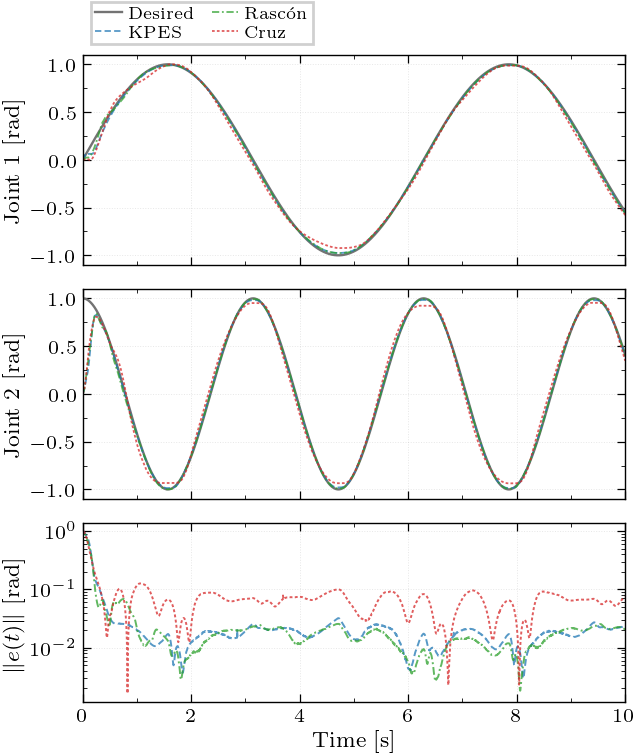

In [20]:
# ── Controller comparison: trajectory tracking & error norm ──────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import AutoMinorLocator, LogLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.io import loadmat
from pathlib import Path

# ═══════════════════════════════════════════════════════════════════════
# IEEE style  (single column)
# ═══════════════════════════════════════════════════════════════════════
COL_W  = 3.5
FIG_H  = 4.2

mpl.rcParams.update({
    'text.usetex':        True,
    'text.latex.preamble': r'\usepackage{amsmath}\usepackage{amssymb}',
    'font.family':        'serif',
    'font.serif':         ['Computer Modern Roman'],
    'font.size':          8,
    'axes.labelsize':     8,
    'axes.titlesize':     9,
    'legend.fontsize':    6,
    'xtick.labelsize':    7,
    'ytick.labelsize':    7,
    'lines.linewidth':    0.75,
    'axes.linewidth':     0.5,
    'axes.grid':          True,
    'axes.grid.which':    'major',
    'grid.alpha':         0.30,
    'grid.linewidth':     0.35,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   3,
    'ytick.major.size':   3,
    'xtick.minor.size':   1.5,
    'ytick.minor.size':   1.5,
    'xtick.major.width':  0.45,
    'ytick.major.width':  0.45,
    'xtick.minor.width':  0.3,
    'ytick.minor.width':  0.3,
    'xtick.top':          True,
    'ytick.right':        True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.labelpad':      2.0,
    'xtick.major.pad':    2.0,
    'ytick.major.pad':    2.0,
    'legend.frameon':       True,
    'legend.framealpha':    0.92,
    'legend.edgecolor':     '0.80',
    'legend.fancybox':      False,
    'legend.borderpad':     0.3,
    'legend.handlelength':  1.6,
    'legend.handletextpad': 0.4,
    'legend.columnspacing': 0.8,
    'legend.labelspacing':  0.25,
    'figure.dpi':         200,
    'savefig.dpi':        600,
    'savefig.bbox':       'tight',
    'savefig.pad_inches': 0.015,
    'pdf.fonttype':       42,
    'ps.fonttype':        42,
})

# ── Colours ──────────────────────────────────────────────────────────
c_des   = '0.45'
c_kpes  = '#1f77b4'
c_rasc  = '#2ca02c'
c_cruz  = '#d62728'
c_rect  = '0.5'

ALPHA = 0.75

# ── Load data ────────────────────────────────────────────────────────
data_dir = '/Users/lars/Documents/GitHub/Master-Research-Project/Python Code'

controllers = []

kpes = loadmat(str(Path(data_dir) / 'KPES_pert_a1_0.000_a2_0.000.mat'))
controllers.append({
    'name':  'KPES',
    'color': c_kpes,
    'dash':  (3.5, 1.8),
    't':         kpes['t'].flatten(),
    'q_desired': kpes['q_desired'],
    'q_meas':    kpes['q_meas'],
    'e_track':   kpes['e_track'],
})

for fname, label, color, dash in [
    ('RasconIET_control.mat', r"Rasc\'{o}n", c_rasc, (4, 1.5, 1, 1.5)),
    ('Cruz_control.mat',      'Cruz',         c_cruz, (1.5, 1.2)),
]:
    m = loadmat(str(Path(data_dir) / fname))
    controllers.append({
        'name':  label,
        'color': color,
        'dash':  dash,
        't':         m['t'].flatten(),
        'q_desired': m['q_desired'],
        'q_meas':    m['q_meas'],
        'e_track':   m['e_track'],
    })

for c in controllers:
    c['e_norm'] = np.linalg.norm(c['e_track'], axis=1)
    c['e_rms']  = np.sqrt(np.mean(c['e_norm']**2))

# ── Zoom window ──────────────────────────────────────────────────────
ZOOM_T = (0.0, 2.0)


def add_zoom_inset(ax_parent, t_arrays, y_arrays, colors, dashes,
                   alphas, zoom_xlim, inset_loc='upper right',
                   width='45%', height='50%', is_log=False):
    """Add an inset with a rectangle on the parent marking the zoom region."""
    ax_ins = inset_axes(ax_parent, width=width, height=height,
                        loc=inset_loc, borderpad=0.4)

    for t, y, col, d, a in zip(t_arrays, y_arrays, colors, dashes, alphas):
        if d is None:
            ax_ins.plot(t, y, color=col, linewidth=0.6, alpha=a)
        else:
            ax_ins.plot(t, y, color=col, linewidth=0.4, alpha=a,
                        linestyle='--', dashes=d)

    ax_ins.set_xlim(*zoom_xlim)

    # Auto y-limits from data in zoom window
    y_vals = []
    for t, y in zip(t_arrays, y_arrays):
        mask = (t >= zoom_xlim[0]) & (t <= zoom_xlim[1])
        if mask.any():
            y_vals.append(y[mask])
    y_all = np.concatenate(y_vals)
    y_margin = 0.1 * (y_all.max() - y_all.min() + 1e-12)
    ax_ins.set_ylim(y_all.min() - y_margin, y_all.max() + y_margin)

    if is_log:
        ax_ins.set_yscale('log')
        # Recompute for log
        y_pos = y_all[y_all > 0]
        if len(y_pos) > 0:
            ax_ins.set_ylim(y_pos.min() * 0.5, y_pos.max() * 2.0)

    ax_ins.tick_params(labelsize=5, direction='in',
                       length=2, width=0.3, pad=1.5)
    ax_ins.xaxis.set_minor_locator(AutoMinorLocator(2))
    if not is_log:
        ax_ins.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax_ins.set_facecolor('white')
    for spine in ax_ins.spines.values():
        spine.set_linewidth(0.4)

    # Draw rectangle on parent showing zoom region
    yl = ax_ins.get_ylim()
    rect = Rectangle((zoom_xlim[0], yl[0]),
                      zoom_xlim[1] - zoom_xlim[0],
                      yl[1] - yl[0],
                      linewidth=0.4, edgecolor=c_rect,
                      facecolor='none', linestyle='--', zorder=5)
    ax_parent.add_patch(rect)

    return ax_ins


# ═══════════════════════════════════════════════════════════════════════
# Figure
# ═══════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(
    3, 1, figsize=(COL_W, FIG_H), sharex=True,
    gridspec_kw={'height_ratios': [1, 1, 0.85], 'hspace': 0.12},
)

# ── Joint 1 & 2 ─────────────────────────────────────────────────────
for j, ax in enumerate(axes[:2]):
    ax.plot(controllers[0]['t'], controllers[0]['q_desired'][:, j],
            color=c_des, linewidth=0.85)
    for c in controllers:
        ax.plot(c['t'], c['q_meas'][:, j],
                color=c['color'], linewidth=0.65, alpha=ALPHA,
                linestyle='--', dashes=c['dash'])
    ax.set_ylabel(r'Joint %d [rad]' % (j+1))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))

    # Inset
    t_arr  = [controllers[0]['t']] + [c['t'] for c in controllers]
    y_arr  = [controllers[0]['q_desired'][:, j]] + [c['q_meas'][:, j] for c in controllers]
    cols   = [c_des] + [c['color'] for c in controllers]
    ds     = [None]  + [c['dash']  for c in controllers]
    alphs  = [1.0]   + [ALPHA]*len(controllers)

    # add_zoom_inset(ax, t_arr, y_arr, cols, ds, alphs, ZOOM_T)

# ── Error norm ───────────────────────────────────────────────────────
ax = axes[2]
for c in controllers:
    ax.plot(c['t'], c['e_norm'],
            color=c['color'], linewidth=0.7, alpha=ALPHA,
            linestyle='--', dashes=c['dash'])

ax.set_yscale('log')
ax.set_ylabel(r'$\|e(t)\|$ [rad]')
ax.set_xlabel(r'Time [s]')

ax.yaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax.yaxis.set_minor_locator(
    LogLocator(base=10, subs=np.arange(2, 10)*0.1, numticks=12))
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.xaxis.set_minor_locator(AutoMinorLocator(2))

# Inset on error norm
t_arr_e  = [c['t']      for c in controllers]
y_arr_e  = [c['e_norm'] for c in controllers]
cols_e   = [c['color']  for c in controllers]
ds_e     = [c['dash']   for c in controllers]
alphs_e  = [ALPHA]*len(controllers)

# add_zoom_inset(ax, t_arr_e, y_arr_e, cols_e, ds_e, alphs_e,
#                (0.0, 0.5), is_log=True)

# # RMSE annotations
# for i, c in enumerate(controllers):
#     ax.annotate(
#         r'%s: %.4f rad' % (c['name'], c['e_rms']),
#         xy=(0.03, 0.92 - i*0.13), xycoords='axes fraction',
#         fontsize=5.5, color=c['color'], ha='left', va='top',
#         bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))

for i, c in enumerate(controllers):
    print((c['name'], float(c['e_rms'])))
#         xy=(0.03, 0.92 - i*0.13), xycoords='axes fraction',
#         fontsize=5.5, color=c['color'], ha='left', va='top',
#         bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8)))

# ── Shared top legend ────────────────────────────────────────────────
handles = [
    Line2D([], [], color=c_des, ls='-', lw=0.85, label='Desired'),
]
for c in controllers:
    handles.append(
        Line2D([], [], color=c['color'], ls='--', dashes=c['dash'],
               lw=0.65, alpha=ALPHA, label=c['name']))

axes[0].legend(
    handles=handles,
    loc='lower left',
    bbox_to_anchor=(0.0, 1.01),
    ncol=2,
    columnspacing=1.0,
    handletextpad=0.4,
    borderpad=0.25,
    fontsize=6,
)

for ax in axes:
    ax.set_xlim(controllers[0]['t'][0], controllers[0]['t'][-1])

fig.align_ylabels(axes)

out_dir = Path(data_dir)
fig.savefig(str(out_dir / 'controller_comparison.pdf'))
fig.savefig(str(out_dir / 'controller_comparison.png'))
plt.show()

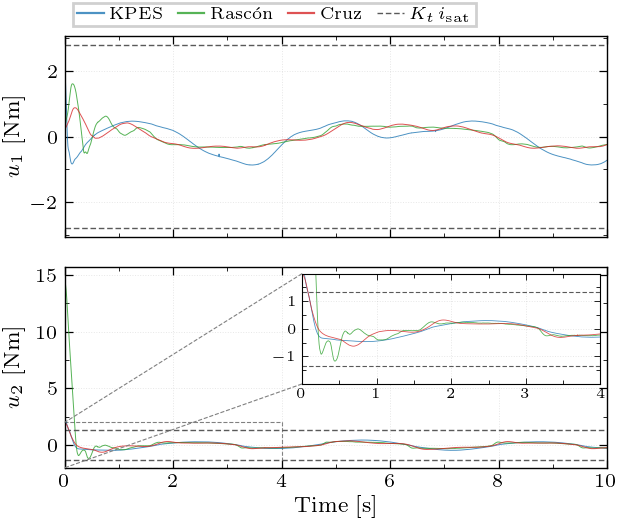

In [20]:
# ── Controller comparison: control inputs + saturation limits ────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from scipy.io import loadmat
from pathlib import Path

# ═══════════════════════════════════════════════════════════════════════
# IEEE style  (single column)
# ═══════════════════════════════════════════════════════════════════════
COL_W  = 3.5
FIG_H  = 2.8          # slightly taller to accommodate inset

mpl.rcParams.update({
    'text.usetex':        True,
    'text.latex.preamble': r'\usepackage{amsmath}\usepackage{amssymb}',
    'font.family':        'serif',
    'font.serif':         ['Computer Modern Roman'],
    'font.size':          8,
    'axes.labelsize':     8,
    'axes.titlesize':     9,
    'legend.fontsize':    6,
    'xtick.labelsize':    7,
    'ytick.labelsize':    7,
    'lines.linewidth':    0.75,
    'axes.linewidth':     0.5,
    'axes.grid':          True,
    'axes.grid.which':    'major',
    'grid.alpha':         0.30,
    'grid.linewidth':     0.35,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   3,
    'ytick.major.size':   3,
    'xtick.minor.size':   1.5,
    'ytick.minor.size':   1.5,
    'xtick.major.width':  0.45,
    'ytick.major.width':  0.45,
    'xtick.minor.width':  0.3,
    'ytick.minor.width':  0.3,
    'xtick.top':          True,
    'ytick.right':        True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.labelpad':      2.0,
    'xtick.major.pad':    2.0,
    'ytick.major.pad':    2.0,
    'legend.frameon':       True,
    'legend.framealpha':    0.92,
    'legend.edgecolor':     '0.80',
    'legend.fancybox':      False,
    'legend.borderpad':     0.3,
    'legend.handlelength':  1.6,
    'legend.handletextpad': 0.4,
    'legend.columnspacing': 0.8,
    'legend.labelspacing':  0.25,
    'figure.dpi':         200,
    'savefig.dpi':        600,
    'savefig.bbox':       'tight',
    'savefig.pad_inches': 0.015,
    'pdf.fonttype':       42,
    'ps.fonttype':        42,
})

# ── Colours ──────────────────────────────────────────────────────────
c_kpes  = '#1f77b4'
c_rasc  = '#2ca02c'
c_cruz  = '#d62728'
c_sat   = '0.35'

ALPHA = 0.80

# ── Torque saturation limits ─────────────────────────────────────────
Kt1    = 3.018583
i_sat1 = 0.92
Kt2    = 1.111065
i_sat2 = 1.2

u_max = [Kt1 * i_sat1, Kt2 * i_sat2]

# ── Load data ────────────────────────────────────────────────────────
data_dir = '/Users/lars/Documents/GitHub/Master-Research-Project/Python Code'

controllers = []

kpes = loadmat(str(Path(data_dir) / 'KPES_pert_a1_0.000_a2_0.000.mat'))
controllers.append({
    'name':  'KPES',
    'color': c_kpes,
    't':         kpes['t'].flatten(),
    'u_total':   kpes['u_total'],
})

for fname, label, color in [
    ('RasconIET_control.mat', r"Rasc\'{o}n", c_rasc),
    ('Cruz_control.mat',      'Cruz',         c_cruz),
]:
    m = loadmat(str(Path(data_dir) / fname))
    controllers.append({
        'name':  label,
        'color': color,
        't':         m['t'].flatten(),
        'u_total':   m['u_total'],
    })

# ═══════════════════════════════════════════════════════════════════════
# Figure
# ═══════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(
    2, 1, figsize=(COL_W, FIG_H), sharex=True,
    gridspec_kw={'hspace': 0.15},
)

for j, ax in enumerate(axes):
    for c in controllers:
        ax.plot(c['t'], c['u_total'][:, j],
                color=c['color'], linewidth=0.35, alpha=ALPHA,
                linestyle='-')
    ax.axhline( u_max[j], color=c_sat, ls='--', lw=0.5, dashes=(4, 2))
    ax.axhline(-u_max[j], color=c_sat, ls='--', lw=0.5, dashes=(4, 2))
    ax.set_ylabel(r'$u_%d$ [Nm]' % (j+1))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.set_xlim(controllers[0]['t'][0], controllers[0]['t'][-1])

axes[1].set_xlabel(r'Time [s]')

# ── Inset on Joint 2: zoom around saturation region ─────────────────
ax_ins = inset_axes(axes[1], width='55%', height='55%',
                    loc='upper right', borderpad=0.4)

for c in controllers:
    ax_ins.plot(c['t'], c['u_total'][:, 1],
                color=c['color'], linewidth=0.3, alpha=ALPHA,
                linestyle='-')
ax_ins.axhline( u_max[1], color=c_sat, ls='--', lw=0.4, dashes=(4, 2))
ax_ins.axhline(-u_max[1], color=c_sat, ls='--', lw=0.4, dashes=(4, 2))

# Zoom range
ax_ins.set_xlim(0, 4)
ax_ins.set_ylim(-u_max[1]*1.5, u_max[1]*1.5)

ax_ins.tick_params(labelsize=5, direction='in',
                   length=2, width=0.3, pad=1.5)
ax_ins.xaxis.set_minor_locator(AutoMinorLocator(2))
ax_ins.yaxis.set_minor_locator(AutoMinorLocator(2))
ax_ins.set_facecolor('white')
for spine in ax_ins.spines.values():
    spine.set_linewidth(0.4)

mark_inset(axes[1], ax_ins, loc1=2, loc2=3,
           fc='none', ec='0.5', lw=0.4, ls='--')

# ── Shared top legend ────────────────────────────────────────────────
handles = []
for c in controllers:
    handles.append(
        Line2D([], [], color=c['color'], ls='-',
               lw=0.8, alpha=ALPHA, label=c['name']))
handles.append(
    Line2D([], [], color=c_sat, ls='--', dashes=(4, 2),
           lw=0.5, label=r'$K_t \, i_{\mathrm{sat}}$'))

axes[0].legend(
    handles=handles,
    loc='lower left',
    bbox_to_anchor=(0.0, 1.01),
    ncol=4,
    columnspacing=0.8,
    handletextpad=0.4,
    borderpad=0.25,
    fontsize=6,
)

fig.align_ylabels(axes)

out_dir = Path(data_dir)
fig.savefig(str(out_dir / 'controller_control_input.pdf'))
fig.savefig(str(out_dir / 'controller_control_input.png'))
plt.show()

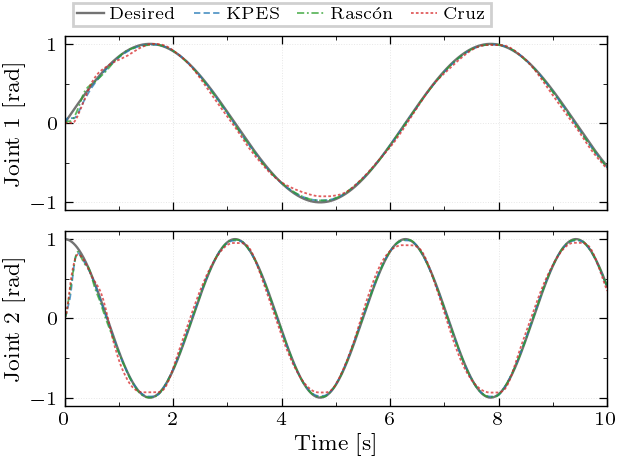

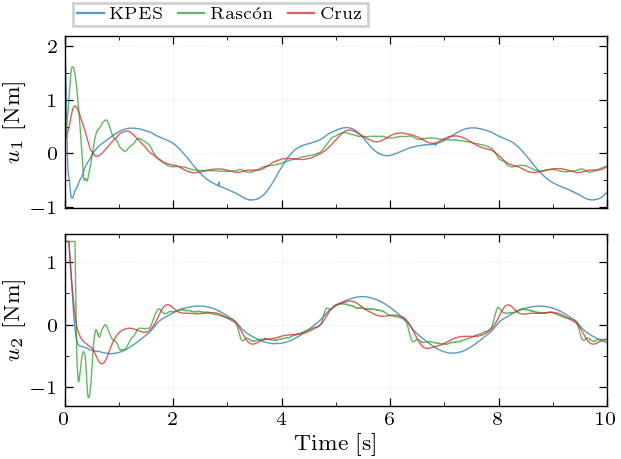

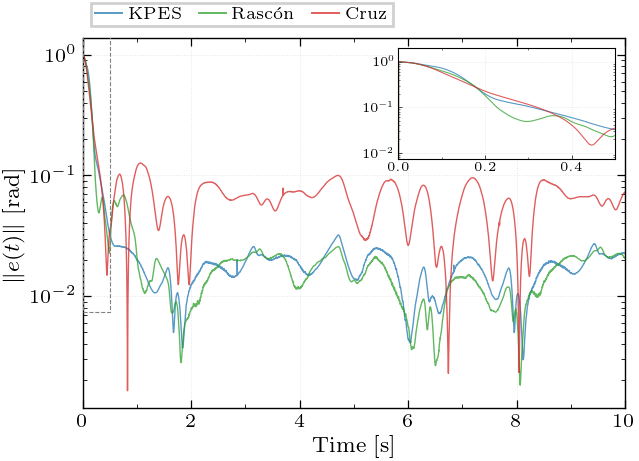

In [39]:
# ── Controller comparison: three separate IEEE figures ────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import AutoMinorLocator, LogLocator, MaxNLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.io import loadmat
from pathlib import Path

# ═══════════════════════════════════════════════════════════════════════
# IEEE style
# ═══════════════════════════════════════════════════════════════════════
COL_W = 3.5

mpl.rcParams.update({
    'text.usetex':        True,
    'text.latex.preamble': r'\usepackage{amsmath}\usepackage{amssymb}',
    'font.family':        'serif',
    'font.serif':         ['Computer Modern Roman'],
    'font.size':          8,
    'axes.labelsize':     8,
    'axes.titlesize':     9,
    'legend.fontsize':    6,
    'xtick.labelsize':    7,
    'ytick.labelsize':    7,
    'lines.linewidth':    0.75,
    'axes.linewidth':     0.5,
    'axes.grid':          True,
    'axes.grid.which':    'major',
    'grid.alpha':         0.30,
    'grid.linewidth':     0.35,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   3,
    'ytick.major.size':   3,
    'xtick.minor.size':   1.5,
    'ytick.minor.size':   1.5,
    'xtick.major.width':  0.45,
    'ytick.major.width':  0.45,
    'xtick.minor.width':  0.3,
    'ytick.minor.width':  0.3,
    'xtick.top':          True,
    'ytick.right':        True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.labelpad':      2.0,
    'xtick.major.pad':    2.0,
    'ytick.major.pad':    2.0,
    'legend.frameon':       True,
    'legend.framealpha':    0.92,
    'legend.edgecolor':     '0.80',
    'legend.fancybox':      False,
    'legend.borderpad':     0.3,
    'legend.handlelength':  1.6,
    'legend.handletextpad': 0.4,
    'legend.columnspacing': 0.8,
    'legend.labelspacing':  0.25,
    'figure.dpi':         200,
    'savefig.dpi':        600,
    'savefig.bbox':       'tight',
    'savefig.pad_inches': 0.015,
    'pdf.fonttype':       42,
    'ps.fonttype':        42,
})

# ── Colours ──────────────────────────────────────────────────────────
c_des   = '0.45'
c_kpes  = '#1f77b4'
c_rasc  = '#2ca02c'
c_cruz  = '#d62728'
c_sat   = '0.35'
c_rect  = '0.5'

ALPHA = 0.75

# ── Torque saturation ────────────────────────────────────────────────
Kt1, i_sat1 = 3.018583, 0.92
Kt2, i_sat2 = 1.111065, 1.2
u_max = [Kt1 * i_sat1, Kt2 * i_sat2]

# ── Load data ────────────────────────────────────────────────────────
data_dir = '/Users/lars/Documents/GitHub/Master-Research-Project/Python Code'

controllers = []

kpes = loadmat(str(Path(data_dir) / 'KPES_pert_a1_0.000_a2_0.000.mat'))
controllers.append({
    'name':  'KPES',
    'color': c_kpes,
    'dash':  (3.5, 1.8),
    't':         kpes['t'].flatten(),
    'q_desired': kpes['q_desired'],
    'q_meas':    kpes['q_meas'],
    'e_track':   kpes['e_track'],
    'u_total':   kpes['u_total'],
})

for fname, label, color, dash in [
    ('RasconIET_control.mat', r"Rasc\'{o}n", c_rasc, (4, 1.5, 1, 1.5)),
    ('Cruz_control.mat',      'Cruz',         c_cruz, (1.5, 1.2)),
]:
    m = loadmat(str(Path(data_dir) / fname))
    controllers.append({
        'name':  label,
        'color': color,
        'dash':  dash,
        't':         m['t'].flatten(),
        'q_desired': m['q_desired'],
        'q_meas':    m['q_meas'],
        'e_track':   m['e_track'],
        'u_total':   m['u_total'],
    })

for c in controllers:
    c['e_norm'] = np.linalg.norm(c['e_track'], axis=1)
    c['e_rms']  = np.sqrt(np.mean(c['e_norm']**2))

out_dir = Path(data_dir)
ZOOM_T = (0.0, 2.0)


# ── Helper: inset zoom ──────────────────────────────────────────────
def add_zoom_inset(ax_parent, t_arrays, y_arrays, colors, dashes,
                   alphas, zoom_xlim, inset_loc='upper right',
                   width='45%', height='50%', is_log=False):
    ax_ins = inset_axes(ax_parent, width=width, height=height,
                        loc=inset_loc, borderpad=0.4)
    for t, y, col, d, a in zip(t_arrays, y_arrays, colors, dashes, alphas):
        if d is None:
            ax_ins.plot(t, y, color=col, linewidth=0.6, alpha=a)
        else:
            ax_ins.plot(t, y, color=col, linewidth=0.4, alpha=a,
                        linestyle='--', dashes=d)
    ax_ins.set_xlim(*zoom_xlim)

    y_vals = []
    for t, y in zip(t_arrays, y_arrays):
        mask = (t >= zoom_xlim[0]) & (t <= zoom_xlim[1])
        if mask.any():
            y_vals.append(y[mask])
    y_all = np.concatenate(y_vals)
    y_margin = 0.1 * (y_all.max() - y_all.min() + 1e-12)
    ax_ins.set_ylim(y_all.min() - y_margin, y_all.max() + y_margin)

    if is_log:
        ax_ins.set_yscale('log')
        y_pos = y_all[y_all > 0]
        if len(y_pos) > 0:
            ax_ins.set_ylim(y_pos.min() * 0.5, y_pos.max() * 2.0)

    ax_ins.tick_params(labelsize=5, direction='in',
                       length=2, width=0.3, pad=1.5)
    ax_ins.xaxis.set_minor_locator(AutoMinorLocator(2))
    if not is_log:
        ax_ins.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax_ins.set_facecolor('white')
    for spine in ax_ins.spines.values():
        spine.set_linewidth(0.4)

    yl = ax_ins.get_ylim()
    rect = Rectangle((zoom_xlim[0], yl[0]),
                      zoom_xlim[1] - zoom_xlim[0],
                      yl[1] - yl[0],
                      linewidth=0.4, edgecolor=c_rect,
                      facecolor='none', linestyle='--', zorder=5)
    ax_parent.add_patch(rect)
    return ax_ins


# ── Legend handles ───────────────────────────────────────────────────
h_track = [Line2D([], [], color=c_des, ls='-', lw=0.85, label='Desired')]
for c in controllers:
    h_track.append(
        Line2D([], [], color=c['color'], ls='--', dashes=c['dash'],
               lw=0.65, alpha=ALPHA, label=c['name']))

h_ctrl = []
for c in controllers:
    h_ctrl.append(
        Line2D([], [], color=c['color'], ls='-',
               lw=0.8, alpha=ALPHA, label=c['name']))

h_err = []
for c in controllers:
    h_err.append(
        Line2D([], [], color=c['color'], ls='-',
               lw=0.7, alpha=ALPHA, label=c['name']))


# ═══════════════════════════════════════════════════════════════════════
# Figure 1 – Position tracking
# ═══════════════════════════════════════════════════════════════════════
fig1, axes1 = plt.subplots(
    2, 1, figsize=(COL_W, 2.4), sharex=True,
    gridspec_kw={'hspace': 0.12},
)

for j, ax in enumerate(axes1):
    ax.plot(controllers[0]['t'], controllers[0]['q_desired'][:, j],
            color=c_des, linewidth=0.85)
    for c in controllers:
        ax.plot(c['t'], c['q_meas'][:, j],
                color=c['color'], linewidth=0.65, alpha=ALPHA,
                linestyle='--', dashes=c['dash'])
    ax.set_ylabel(r'Joint %d [rad]' % (j+1))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.set_xlim(controllers[0]['t'][0], controllers[0]['t'][-1])

axes1[1].set_xlabel(r'Time [s]')

axes1[0].legend(
    handles=h_track,
    loc='lower left', bbox_to_anchor=(0.0, 1.01),
    ncol=4, columnspacing=1.0, handletextpad=0.4, borderpad=0.25, fontsize=6,
)

fig1.align_ylabels(axes1)
fig1.savefig(str(out_dir / 'controller_tracking.pdf'))
fig1.savefig(str(out_dir / 'controller_tracking.png'))
plt.show()


# ═══════════════════════════════════════════════════════════════════════
# Figure 2 – Control inputs
# ═══════════════════════════════════════════════════════════════════════
fig2, axes2 = plt.subplots(
    2, 1, figsize=(COL_W, 2.4), sharex=True,
    gridspec_kw={'hspace': 0.15},
)

for j, ax in enumerate(axes2):
    for c in controllers:
        ax.plot(c['t'], np.minimum(c['u_total'][:, j], u_max[j]),
                color=c['color'], linewidth=0.5, alpha=ALPHA,
                linestyle='-')
    ax.set_ylabel(r'$u_%d$ [Nm]' % (j+1))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.set_xlim(controllers[0]['t'][0], controllers[0]['t'][-1])

axes2[1].set_xlabel(r'Time [s]')

axes2[0].legend(
    handles=h_ctrl,
    loc='lower left', bbox_to_anchor=(0.0, 1.01),
    ncol=4, columnspacing=0.8, handletextpad=0.4, borderpad=0.25, fontsize=6,
)

fig2.align_ylabels(axes2)
fig2.savefig(str(out_dir / 'controller_control_input.pdf'))
fig2.savefig(str(out_dir / 'controller_control_input.png'))
plt.show()


# ═══════════════════════════════════════════════════════════════════════
# Figure 3 – Error norm  (with inset, fixed tick overlap)
# ═══════════════════════════════════════════════════════════════════════
fig3, ax3 = plt.subplots(figsize=(COL_W, 2.4))

for c in controllers:
    ax3.plot(c['t'], c['e_norm'],
             color=c['color'], linewidth=0.5, alpha=ALPHA,
             linestyle='-')

ax3.set_yscale('log')
ax3.set_ylabel(r'$\|e(t)\|$ [rad]')
ax3.set_xlabel(r'Time [s]')
ax3.set_xlim(controllers[0]['t'][0], controllers[0]['t'][-1])

ax3.yaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax3.yaxis.set_minor_locator(
    LogLocator(base=10, subs=np.arange(2, 10)*0.1, numticks=12))
ax3.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax3.xaxis.set_minor_locator(AutoMinorLocator(2))

# Inset zoom – placed with padding away from parent ticks
ax_ins = inset_axes(ax3, width='40%', height='30%',
                    loc='upper right', borderpad=0.6)

for c in controllers:
    ax_ins.plot(c['t'], c['e_norm'],
                color=c['color'], linewidth=0.4, alpha=ALPHA,
                linestyle='-')

ax_ins.set_xlim(0.0, 0.5)
ax_ins.set_yscale('log')

# Auto y from data in window
y_vals = []
for c in controllers:
    mask = (c['t'] >= 0.0) & (c['t'] <= 0.5)
    y_pos = c['e_norm'][mask]
    y_pos = y_pos[y_pos > 0]
    if len(y_pos) > 0:
        y_vals.append(y_pos)
y_all = np.concatenate(y_vals)
ax_ins.set_ylim(y_all.min() * 0.5, y_all.max() * 2.0)

# Inset ticks: fewer, smaller, no minor labels, no right/top ticks
ax_ins.tick_params(labelsize=4.5, direction='in',
                   length=1.5, width=0.25, pad=1.0)
ax_ins.tick_params(which='minor', length=0.8, width=0.2)
ax_ins.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=False))
ax_ins.xaxis.set_minor_locator(AutoMinorLocator(2))
ax_ins.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax_ins.tick_params(top=False, right=False)

ax_ins.set_facecolor('white')
for spine in ax_ins.spines.values():
    spine.set_linewidth(0.4)

# Rectangle on parent
yl_ins = ax_ins.get_ylim()
rect = Rectangle((0.0, yl_ins[0]),
                  0.5, yl_ins[1] - yl_ins[0],
                  linewidth=0.4, edgecolor=c_rect,
                  facecolor='none', linestyle='--', zorder=5)
ax3.add_patch(rect)

# Legend
ax3.legend(
    handles=h_err,
    loc='lower left', bbox_to_anchor=(0.0, 1.01),
    ncol=3, columnspacing=1.0, handletextpad=0.4, borderpad=0.25, fontsize=6,
)

fig3.savefig(str(out_dir / 'controller_error.pdf'))
fig3.savefig(str(out_dir / 'controller_error.png'))
plt.show()

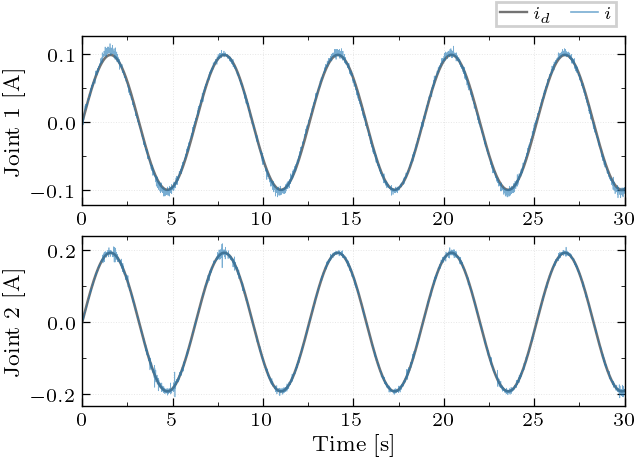

In [19]:
# ── Current/torque tracking (IEEE single-column, both joints) ────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
from scipy.io import loadmat
from pathlib import Path

# ═══════════════════════════════════════════════════════════════════════
# IEEE style
# ═══════════════════════════════════════════════════════════════════════
COL_W = 3.5

mpl.rcParams.update({
    'text.usetex':        True,
    'text.latex.preamble': r'\usepackage{amsmath}\usepackage{amssymb}',
    'font.family':        'serif',
    'font.serif':         ['Computer Modern Roman'],
    'font.size':          8,
    'axes.labelsize':     8,
    'axes.titlesize':     9,
    'legend.fontsize':    6,
    'xtick.labelsize':    7,
    'ytick.labelsize':    7,
    'lines.linewidth':    0.75,
    'axes.linewidth':     0.5,
    'axes.grid':          True,
    'axes.grid.which':    'major',
    'grid.alpha':         0.30,
    'grid.linewidth':     0.35,
    'xtick.direction':    'in',
    'ytick.direction':    'in',
    'xtick.major.size':   3,
    'ytick.major.size':   3,
    'xtick.minor.size':   1.5,
    'ytick.minor.size':   1.5,
    'xtick.major.width':  0.45,
    'ytick.major.width':  0.45,
    'xtick.minor.width':  0.3,
    'ytick.minor.width':  0.3,
    'xtick.top':          True,
    'ytick.right':        True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.labelpad':      2.0,
    'xtick.major.pad':    2.0,
    'ytick.major.pad':    2.0,
    'legend.frameon':       True,
    'legend.framealpha':    0.92,
    'legend.edgecolor':     '0.80',
    'legend.fancybox':      False,
    'legend.borderpad':     0.3,
    'legend.handlelength':  1.6,
    'legend.handletextpad': 0.4,
    'legend.columnspacing': 0.8,
    'legend.labelspacing':  0.25,
    'figure.dpi':         200,
    'savefig.dpi':        600,
    'savefig.bbox':       'tight',
    'savefig.pad_inches': 0.015,
    'pdf.fonttype':       42,
    'ps.fonttype':        42,
})

# ── Colours ──────────────────────────────────────────────────────────
c_des = '0.45'        # grey – desired / reference
c_act = '#1f77b4'     # blue – actual / measured
A_ACT = 0.6

# ── Load data ────────────────────────────────────────────────────────
data_dir = Path('.')   # <-- ADJUST

mat1 = loadmat(str(data_dir / 'torque_control_M1.mat'))
mat2 = loadmat(str(data_dir / 'torque_control_M2.mat'))

simout1 = mat1['simout']   # (N, 4)
simout2 = mat2['simout']

i_des1, i_act1 = simout1[:, 0], simout1[:, 1]
i_des2, i_act2 = simout2[:, 0], simout2[:, 1]

dt = 0.01
t1 = np.arange(len(i_des1)) * dt
t2 = np.arange(len(i_des2)) * dt

# ═══════════════════════════════════════════════════════════════════════
# Figure – Joint 1 & 2 current tracking
# ═══════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(
    2, 1, figsize=(COL_W, 2.4), sharex=False,
    gridspec_kw={'hspace': 0.18},
)

for j, (t, i_d, i_a, ax) in enumerate(zip(
        [t1, t2], [i_des1, i_des2], [i_act1, i_act2], axes)):
    ax.plot(t, i_d, color=c_des, linewidth=0.95)
    ax.plot(t, i_a, color=c_act, linewidth=0.25, alpha=A_ACT)
    ax.set_ylabel(r'Joint %d [A]' % (j+1))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.set_xlim(t[0], t[-1])

axes[1].set_xlabel(r'Time [s]')

# ── Shared top legend ────────────────────────────────────────────────
handles = [
    Line2D([], [], color=c_des, ls='-',  lw=0.85,              label=r'$i_d$'),
    Line2D([], [], color=c_act, ls='-',  lw=0.6,  alpha=A_ACT, label=r'$i$'),
]
axes[0].legend(
    handles=handles,
    loc='lower right', bbox_to_anchor=(1.0, 1.01),
    ncol=2, columnspacing=1.2, handletextpad=0.4, borderpad=0.25,
)

fig.align_ylabels(axes)

fig.savefig(str(data_dir / 'current_tracking.pdf'))
fig.savefig(str(data_dir / 'current_tracking.png'))
plt.show()